# Spiral Neural network 


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import LinearSegmentedColormap


In [3]:
def spiral(n, seed):
    r = np.random.default_rng(seed)
    t = np.sqrt(r.random(n)) * 3 * np.pi   # n valori tra 0 e 3π
    a = np.c_[t*np.cos(t), t*np.sin(t)] / 10
    X = np.vstack([a, -a]) + r.normal(0, .02, (2*n, 2))
    y = np.r_[np.zeros(n), np.ones(n)][:, None]
    return X, y
    


In [4]:
X, y = spiral(10000, 0)
X_test, y_test = spiral(10000, 1)

rng=np.random.default_rng(42)

sizes = [2, 32, 32, 1]

# weight initialization
W = [rng.normal(0, 1 /np.sqrt(i), (i , o)) for i, o in zip(sizes[:-1], sizes[1:])]

y_t = 2*y - 1
y_test_t = 2*y_test - 1

In [5]:
print("Weight structure", [w.shape for w in W])

Weight structure [(2, 32), (32, 32), (32, 1)]


In [6]:
# Bais initialization
b = [np.zeros( o)for o in sizes[1:]]



In [7]:
# forward propagation 
def forward(X, W, b):
    a =[X]
    for w, b in zip (W, b):
        z = a [-1] @ w+b
        a.append(np.tanh(z))
    return a
                
                            

In [8]:
# Back propagation 

def step(lr=0.5):
    # 1) FORWARD: calcola tutte le attivazioni e quindi l'uscita
    a = forward(X, W, b)

    # 2) ERRORE: derivata della loss (½·MSE) rispetto all'uscita
    delta = a[-1] - y_t

    # 3) BACKPROP: dall'ultimo strato al primo
    gnorm = 0
    for i in range(len(W)-1, -1, -1):
        delta  = delta * (1 - a[i+1]**2)         # attraversa la tanh → dL/dz
        grad_b = np.mean(delta, axis=0)          # dL/db
        grad_W = a[i].T @ delta / len(X)         # dL/dW
        delta  = delta @ W[i].T                  # errore per lo strato prima (vecchi pesi)

        # 4) DISCESA DEL GRADIENTE: W ← W − lr·∇L
        b[i] -= lr * grad_b
        W[i] -= lr * grad_W

        gnorm += np.sum(grad_W**2) + np.sum(grad_b**2)

    loss = 0.5 * np.mean((a[-1] - y_t)**2)
    return loss, np.sqrt(gnorm)


In [9]:
for epoch in range(3000):
    loss, g = step()
    if epoch % 300 == 0:
        print(f"epoch {epoch:4d}  loss {loss:.4f}  |grad| {g:.4f}")

epoch    0  loss 0.4988  |grad| 0.4881
epoch  300  loss 0.2985  |grad| 0.3588
epoch  600  loss 0.2518  |grad| 0.5923
epoch  900  loss 0.1220  |grad| 0.0199
epoch 1200  loss 0.0646  |grad| 0.0160
epoch 1500  loss 0.0451  |grad| 0.0365
epoch 1800  loss 0.0220  |grad| 0.0478
epoch 2100  loss 0.0063  |grad| 0.0056
epoch 2400  loss 0.0036  |grad| 0.0032
epoch 2700  loss 0.0025  |grad| 0.0021


epoch    0  loss 0.0020  |grad| 0.0016
epoch  500  loss 0.0016  |grad| 0.0011
epoch 1000  loss 0.0013  |grad| 0.0009
epoch 1500  loss 0.0012  |grad| 0.0007
epoch 2000  loss 0.0011  |grad| 0.0006
epoch 2500  loss 0.0010  |grad| 0.0005
epoch 3000  loss 0.0009  |grad| 0.0005
epoch 3500  loss 0.0009  |grad| 0.0004
epoch 4000  loss 0.0008  |grad| 0.0004
epoch 4500  loss 0.0008  |grad| 0.0003
accuracy train: 0.9997  test: 0.99985


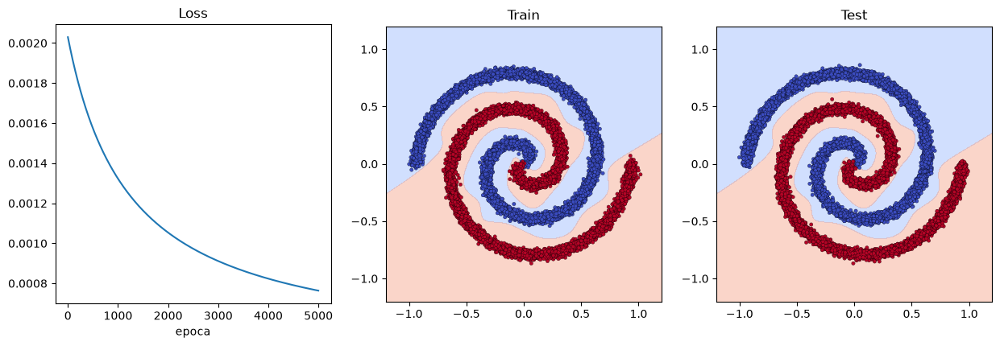

In [10]:
history = []
for epoch in range(5000):
    loss, g = step()
    history.append(loss)
    if epoch % 500 == 0:
        print(f"epoch {epoch:4d}  loss {loss:.4f}  |grad| {g:.4f}")

acc = lambda X_, y_: np.mean(np.sign(forward(X_, W, b)[-1]) == y_)
print("accuracy train:", acc(X, y_t), " test:", acc(X_test, y_test_t))

xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 300), np.linspace(-1.2, 1.2, 300))
Z = forward(np.c_[xx.ravel(), yy.ravel()], W, b)[-1].reshape(xx.shape)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
ax[0].plot(history); ax[0].set_title("Loss"); ax[0].set_xlabel("epoca")
for k, (X_, y_, name) in enumerate([(X, y, "Train"), (X_test, y_test, "Test")], start=1):
    ax[k].contourf(xx, yy, Z, levels=[-1, 0, 1], cmap="coolwarm", alpha=0.4)
    ax[k].scatter(X_[:, 0], X_[:, 1], c=y_.ravel(), cmap="coolwarm", s=10,
                  edgecolors="k", linewidths=0.2)
    ax[k].set_title(name); ax[k].set_aspect("equal")
plt.show()

In [11]:
from IPython.display import HTML

rng = np.random.default_rng(42)
sizes = [2, 32, 32, 1]
W = [rng.normal(0, 1/np.sqrt(i), (i, o)) for i, o in zip(sizes[:-1], sizes[1:])]
b = [np.zeros(o) for o in sizes[1:]]

xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 150), np.linspace(-1.2, 1.2, 150))
grid = np.c_[xx.ravel(), yy.ravel()]

n_epochs, every = 3000, 25
frames, losses = [], []
for epoch in range(n_epochs + 1):
    if epoch % every == 0:
        frames.append((epoch, forward(grid, W, b)[-1].reshape(xx.shape)))
    loss, _ = step()
    losses.append(loss)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))

im = ax1.imshow(frames[0][1], extent=[-1.2, 1.2, -1.2, 1.2], origin="lower",
                cmap="coolwarm", vmin=-1, vmax=1, alpha=0.5)
ax1.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="coolwarm", s=10,
            edgecolors="k", linewidths=0.2)
ax1.set_aspect("equal")

ax2.set_xlim(0, n_epochs)
ax2.set_ylim(0, max(losses) * 1.05)
ax2.set_xlabel("epoca")
ax2.set_ylabel("loss")
line, = ax2.plot([], [])

def update(k):
    epoch, Z = frames[k]
    im.set_data(Z)
    ax1.set_title(f"epoca {epoch}")
    line.set_data(np.arange(epoch + 1), losses[:epoch + 1])
    return im, line

anim = animation.FuncAnimation(fig, update, frames=len(frames), interval=60)
plt.close(fig)
HTML(anim.to_jshtml())

Animation size has reached 21175901 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


In [12]:
import time, cupy as cp

A = cp.random.random((4096, 4096), dtype=cp.float32)
cp.cuda.Device().synchronize()
t = time.time(); n = 0
while time.time() - t < 15:
    A @ A
    cp.cuda.Device().synchronize()
    n += 1
dt = time.time() - t
print(f"{n * 2 * 4096**3 / dt / 1e12:.1f} TFLOPS")

c:\Spiral_ neural_network\.venv\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


3.7 TFLOPS


GPU: 21.4 s  ->  4.5 miliardi di pixel-iterazioni/s
CPU: 0.9 s  ->  0.11 miliardi di pixel-iterazioni/s
La GPU è circa 41 volte più veloce


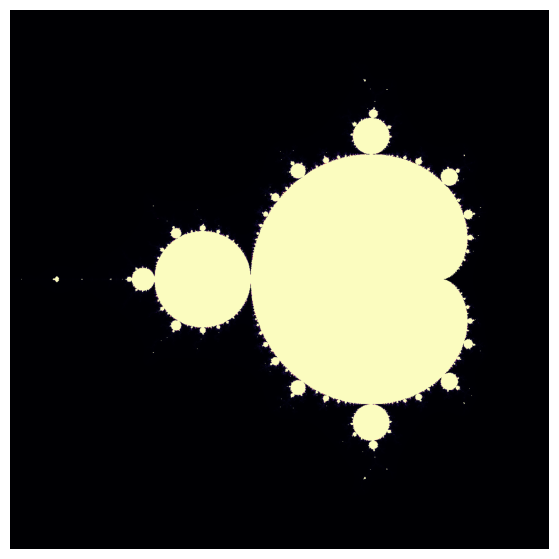

b'NVIDIA RTX A4000 Laptop GPU'
5.7 TFLOPS


In [13]:
import time, numpy as np, cupy as cp
import matplotlib.pyplot as plt

def mandelbrot(xp, n, iters):
    x = xp.linspace(-2.0, 0.8, n, dtype=xp.float32)
    y = xp.linspace(-1.4, 1.4, n, dtype=xp.float32)
    c = (x[None, :] + 1j * y[:, None]).astype(xp.complex64)
    z = xp.zeros_like(c)
    count = xp.zeros(c.shape, dtype=xp.int32)
    with np.errstate(all="ignore"):
        for _ in range(iters):
            z = z * z + c
            count += xp.abs(z) <= 2
    return count

def run(xp, n, iters):
    if xp is cp: cp.cuda.Device().synchronize()
    t = time.time()
    res = mandelbrot(xp, n, iters)
    if xp is cp: cp.cuda.Device().synchronize()
    dt = time.time() - t
    return res, dt, n * n * iters / dt / 1e9

run(cp, 500, 10)                                   # riscaldamento

res_gpu, t_gpu, th_gpu = run(cp, 8000, 1500)       # circa 10-20 s, guarda il grafico Cuda
print(f"GPU: {t_gpu:.1f} s  ->  {th_gpu:.1f} miliardi di pixel-iterazioni/s")

_, t_cpu, th_cpu = run(np, 1000, 100)              # la CPU in piccolo
print(f"CPU: {t_cpu:.1f} s  ->  {th_cpu:.2f} miliardi di pixel-iterazioni/s")
print(f"La GPU è circa {th_gpu / th_cpu:.0f} volte più veloce")

img = cp.asnumpy(res_gpu[::8, ::8])
plt.figure(figsize=(7, 7))
plt.imshow(img, cmap="magma", extent=[-2, 0.8, -1.4, 1.4], origin="lower")
plt.axis("off"); plt.show()

print(cp.cuda.runtime.getDeviceProperties(0)["name"])
A = cp.random.random((8192, 8192), dtype=cp.float32)
cp.cuda.Device().synchronize()

t = time.time()
for _ in range(50):
    C = A @ A
cp.cuda.Device().synchronize()
dt = time.time() - t
print(f"{50 * 2 * 8192**3 / dt / 1e12:.1f} TFLOPS")

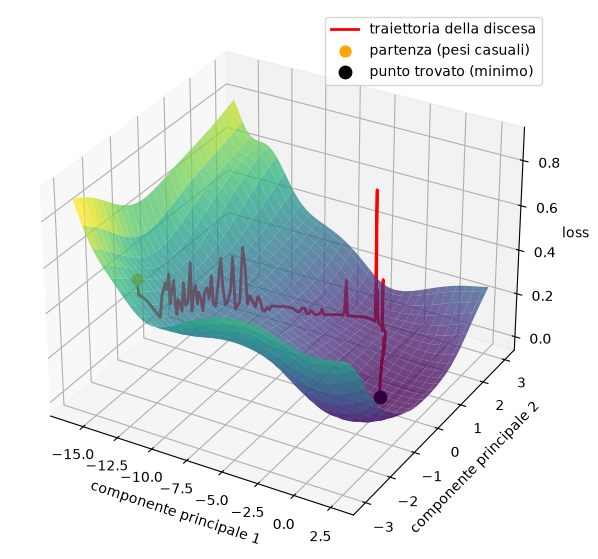

In [14]:



shapes_W = list(zip(sizes[:-1], sizes[1:]))

def flatten(W, b):
    return np.concatenate([w.ravel() for w in W] + [x.ravel() for x in b])

def unflatten(v):
    Ws, bs, k = [], [], 0
    for i, o in shapes_W:
        Ws.append(v[k:k + i*o].reshape(i, o)); k += i*o
    for o in sizes[1:]:
        bs.append(v[k:k + o]); k += o
    return Ws, bs

def loss_of(v):
    Ws, bs = unflatten(v)
    return 0.5 * np.mean((forward(X, Ws, bs)[-1] - y_t) ** 2)

rng = np.random.default_rng(42)
W = [rng.normal(0, 1/np.sqrt(i), (i, o)) for i, o in shapes_W]
b = [np.zeros(o) for o in sizes[1:]]

snap = []
for epoch in range(3001):
    if epoch % 10 == 0:
        snap.append(flatten(W, b))
    step()
snap = np.vstack(snap + [flatten(W, b)])

theta_f = snap[-1]
D = snap - theta_f
_, _, Vt = np.linalg.svd(D, full_matrices=False)
v1, v2 = Vt[0], Vt[1]
px, py = D @ v1, D @ v2
pz = np.array([loss_of(s) for s in snap])

mx, my = 0.2 * np.ptp(px), 0.2 * np.ptp(py)
alphas = np.linspace(px.min() - mx, px.max() + mx, 60)
betas  = np.linspace(py.min() - my, py.max() + my, 60)
Z = np.array([[loss_of(theta_f + a*v1 + c*v2) for a in alphas] for c in betas])
A, B = np.meshgrid(alphas, betas)

fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(A, B, Z, cmap="viridis", alpha=0.75, linewidth=0)
ax.plot(px, py, pz, color="red", lw=2, label="traiettoria della discesa")
ax.scatter(px[0], py[0], pz[0], color="orange", s=60, label="partenza (pesi casuali)")
ax.scatter(0, 0, pz[-1], color="black", s=80, label="punto trovato (minimo)")
ax.set_xlabel("componente principale 1")
ax.set_ylabel("componente principale 2")
ax.set_zlabel("loss")
ax.view_init(elev=30, azim=-60)
ax.legend()
plt.show()